# Punktoperationen

Bei einer **Punktoperation** hängt der neue Grauwert eines Pixels **nur vom alten Grauwert desselben Pixels** ab – Nachbarpixel werden nicht berücksichtigt:

$s = T(r)$

$T$ Transformation (Kennlinie)\
$r$ Ausgangsgrauwert\
$s$ resultierender Grauwert

Weil es bei 8-bit-Bildern nur $L = 256$ mögliche Eingangswerte gibt, lässt sich $T$ vollständig als Tabelle mit 256 Einträgen speichern – eine sogenannte **Lookup-Table (LUT)**. Angewendet wird sie in NumPy einfach per Indizierung: `img_neu = T[img]`.

Bilder: Szene aus dem Film [*Ein Amerikaner in Rom*](https://de.wikipedia.org/wiki/Ein_Amerikaner_in_Rom) (1954) und [Hawke's Bay](https://en.wikipedia.org/wiki/Hawke%27s_Bay), Neuseeland.

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

L = 256  # Zahl der Grauwerte bei 8 bit


def zeige_transformation(T, img, titel="Transformation"):
    # Plot der Transformation
    plt.figure(figsize=(4,4))
    plt.plot(T)
    plt.title(titel)
    plt.xlabel("Input Grauwerte")
    plt.ylabel("Output Grauwerte")
    plt.xlim([0, L-1])
    plt.ylim([0, L-1])
    plt.show()

    # Anwendung
    img_trans = np.round(T[img]).astype(np.uint8)
    plt.imshow(img_trans, cmap="gray", vmin=0, vmax=L-1)
    plt.show()

    # Histogramm
    hist, bin_edges = np.histogram(img_trans, L, [0, L], density=True)
    plt.bar(bin_edges[:-1], hist, width=1)
    plt.xlabel("Grauwerte")
    plt.ylabel("Wahrscheinlichkeit der Pixelwerte")
    plt.xlim([0, L-1])
    plt.show()
    return img_trans


img = cv2.imread("Ein_Amerikaner_in_Rom.png", 0) #Argument 0 sorgt für lesen als Graustufenbild
plt.imshow(img, cmap="gray", vmin=0, vmax=L - 1)
plt.axis("off")
plt.show()

KeyError: 'PolyCollection:kwdoc'

### Grauwerttransformationen (Kennlinien)

Einige klassische Transformationen, jeweils so skaliert, dass $[0, L-1]$ wieder auf $[0, L-1]$ abgebildet wird:

| Transformation | Formel |
|---|---|
| Identität (linear) | $s = r$ |
| Negativ | $s = (L-1) - r$ |
| Potenz / Gamma | $s = (L-1)\left(\frac{r}{L-1}\right)^{\gamma}$, &nbsp; d. h. $s = c\cdot r^{\gamma}$ mit $c=(L-1)^{1-\gamma}$ |
| Logarithmisch | $s = c\cdot\log(1+r)$ mit $c = \frac{L-1}{\log L}$ |
| Exponentiell (inverse Log.) | $s = L^{\,r/(L-1)} - 1$ |
| Schwellwert (binär) | $s = 0$ für $r < t$, sonst $s = L-1$ |

Kommentieren Sie jeweils eine Zeile ein und beobachten Sie Kennlinie, Bild und Histogramm.
Probieren Sie für die Gammakorrektur $\gamma = 0{,}4$ und $\gamma = 2{,}5$: Welche Grauwertbereiche werden gespreizt, welche gestaucht?

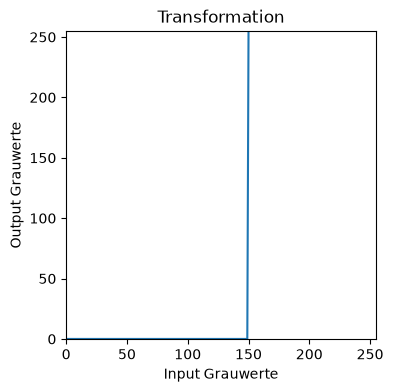

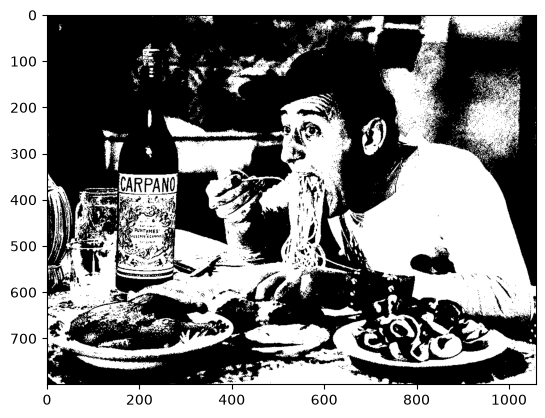

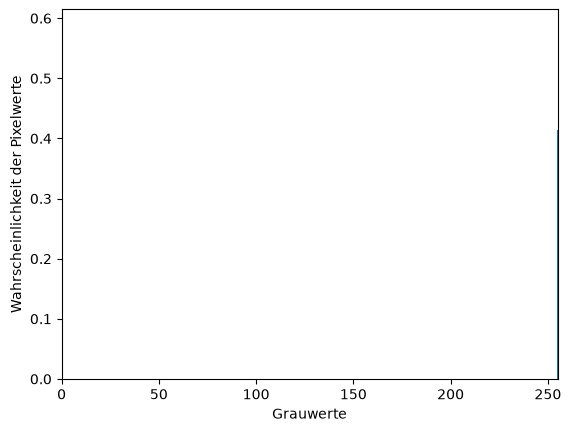

In [ ]:
r = np.arange(L, dtype=float)   # alle möglichen Eingangsgrauwerte 0..255

# Identität
#T = r
# Negativ
#T = (L - 1) - r
# Potenz-/Gammatransformation
gamma = 2.5                   # gamma < 1: hellt dunkle Bereiche auf, gamma > 1: dunkelt ab
#T = (L - 1) * (r / (L - 1))**gamma
# Logarithmische Transformation
#T = (L - 1) / np.log(L) * np.log(1 + r)
# Exponentielle (inverse logarithmische) Transformation
#T = L**(r / (L - 1)) - 1
# Schwellwert (binär)
t = 150                        # Schwellwert
T = np.where(r < t, 0, L - 1)

img_trans = zeige_transformation(T, img)

### Histogramm

Das Histogramm zeigt, **wie oft jeder Grauwert im Bild vorkommt**. Über die Lage der Pixel sagt es nichts aus.

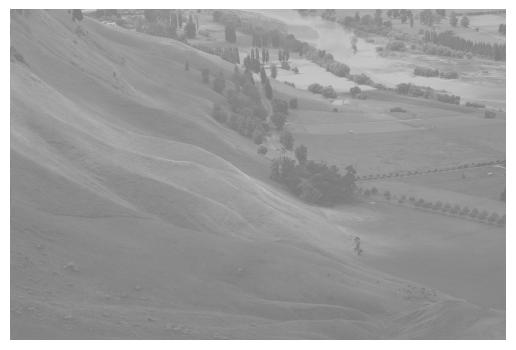

In [ ]:
img = cv2.imread("Hawkes_Bay.png", 0)
plt.imshow(img, cmap="gray", vmin=0, vmax=L - 1)
plt.axis("off")
plt.show()

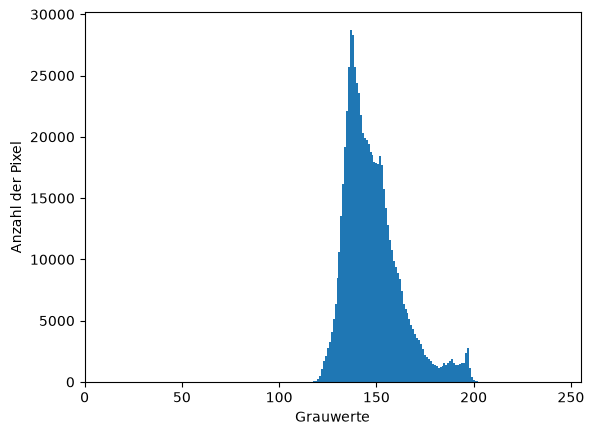

In [ ]:
# 256 Bins über [0, 256): Bin k enthält genau den Grauwert k
hist, bin_edges = np.histogram(img, bins=L, range=(0, L))

plt.bar(bin_edges[:-1], hist, width=1)
plt.xlabel("Grauwerte")
plt.ylabel("Anzahl der Pixel")
plt.xlim([0, L - 1])
plt.show()

### Bins

Bins sind die Klassen des Histogramms. Sie haben gewöhnlich eine konstante Breite, die aber auch variieren kann. Bei 8-bit-Bildern verwendet man meist 256 Bins – einen pro Grauwert.

**Aufgabe:** Reduzieren Sie das Histogramm des obigen Bildes auf 16 Bins. Welche Information geht dabei verloren?

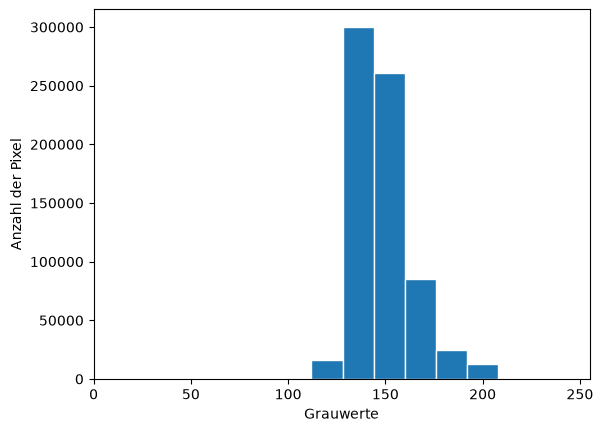

In [ ]:
hist16, bin_edges16 = np.histogram(img, bins = 16, range=(0, L))

plt.bar(bin_edges16[:-1], hist16, width=16, align="edge", edgecolor="white")
plt.xlabel("Grauwerte")
plt.ylabel("Anzahl der Pixel")
plt.xlim([0, L - 1])
plt.show()

### Farbhistogramme

Bei Farbbildern werden gleiche Werte verschiedener Farbkanäle normalerweise **nicht** im selben Bin zusammengefasst. Entweder erstellt man für jeden Kanal ein eigenes Histogramm, oder man verwendet die Helligkeit des zugehörigen Grauwertbildes.

### Histogrammnormalisierung

Teilt man die Anzahl der Pixel je Grauwert durch die Gesamtzahl der Pixel, erhält man die **relative Häufigkeit** jedes Grauwerts. Sie lässt sich als Wahrscheinlichkeit lesen, dass ein zufällig gewähltes Pixel den Grauwert $i$ hat:

$p(i) = \frac{n_i}{n}$

$p(i)$ Wahrscheinlichkeit für Grauwert $i$\
$n_i$ Anzahl der Pixel mit Grauwert $i$\
$n = M \cdot N$ Gesamtzahl der Pixel

Die Summe aller $p(i)$ ist 1. Vorteil: Histogramme unterschiedlich großer Bilder werden vergleichbar.

**Aufgabe:** Berechnen Sie das normierte Histogramm.

Summe der Wahrscheinlichkeiten: 1.0


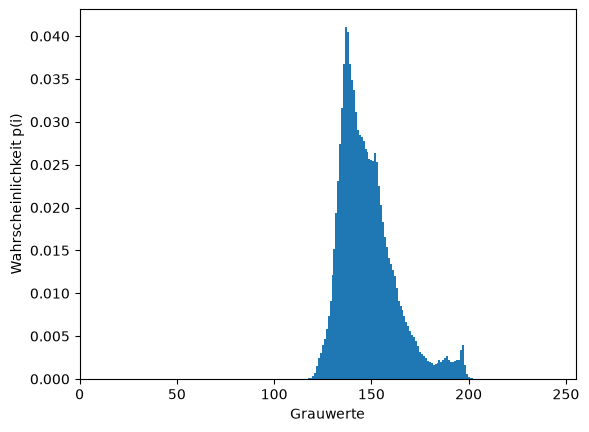

In [ ]:
hist_n, bin_edges = np.histogram(img, bins=L, range=(0, L), density=True)  # Normierung auf Summe = 1
print("Summe der Wahrscheinlichkeiten:", hist_n.sum())

plt.bar(bin_edges[:-1], hist_n, width=1)
plt.xlabel("Grauwerte")
plt.ylabel("Wahrscheinlichkeit p(i)")
plt.xlim([0, L - 1])
plt.show()

### Histogrammverschiebung

Zu allen Grauwerten wird eine Konstante $c$ addiert. Für $c > 0$ wird das Bild heller, für $c < 0$ dunkler. Werte, die den Grauwertbereich verlassen, werden **gesättigt** (auf $0$ bzw. $L-1$ gesetzt):

$T(r) = \begin{cases}0 & \text{falls } r+c<0\\ r+c & \text{falls } 0\leq r+c\leq L-1\\ L-1 & \text{falls } r+c>L-1\end{cases}$

$c$ Verschiebung

**Aufgabe:** Konstruieren Sie die Transformation `T`. Testen Sie $c = -100$ und $c = +60$. Was passiert mit dem Kontrast?

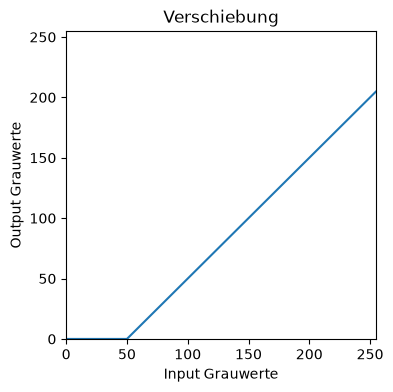

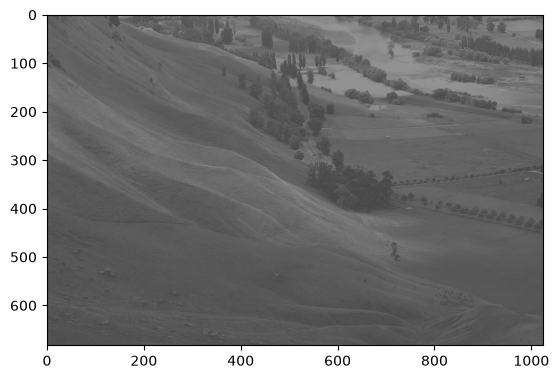

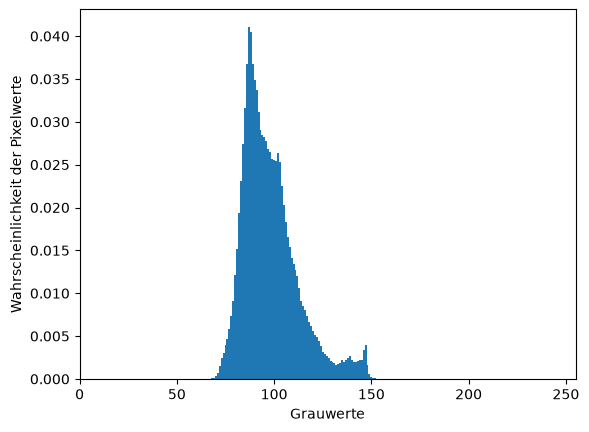

In [ ]:
c = -50   # Verschiebung (negativ = dunkler)

T = np.clip(r + c, 0, L - 1)  # Verschiebung der Grauwerte um c, Werte außerhalb [0, L-1] werden abgeschnitten

img_shift = zeige_transformation(T, img, "Verschiebung")

### Histogrammspreizung und -stauchung

Oft nutzt ein Bild nur einen Teil des Grauwertbereichs. Bei der **linearen Skalierung** wird der vorhandene Bereich $[r_{min}, r_{max}]$ linear auf einen Zielbereich $[s_{min}, s_{max}]$ abgebildet:

$s = T(r) = s_{min} + (s_{max}-s_{min})\,\frac{r-r_{min}}{r_{max}-r_{min}}$

$r_{min}, r_{max}$ kleinster bzw. größter **im Bild vorkommender** Grauwert\
$s_{min}, s_{max}$ Zielbereich

* **Spreizung:** Zielbereich größer als Ausgangsbereich, z. B. $[s_{min}, s_{max}] = [0, L-1]$ → Kontrast steigt. Dann vereinfacht sich die Formel zu $s = (L-1)\,\frac{r-r_{min}}{r_{max}-r_{min}}$.
* **Stauchung:** Zielbereich kleiner als Ausgangsbereich → Kontrast sinkt (z. B. um Platz für Überlagerungen zu schaffen oder Bilder anzugleichen).

Da $r_{min}$ und $r_{max}$ aus dem Bild selbst stammen, wird kein Pixel abgeschnitten.

**Aufgaben:**
1. Bestimmen Sie $r_{min}$ und $r_{max}$ des Bildes. Vergleichen Sie mit dem Histogramm oben – was fällt auf?
2. Konstruieren Sie die Transformation für eine Spreizung auf $[0, L-1]$.
3. Konstruieren Sie die Transformation für eine Stauchung des **gespreizten** Bildes auf $[64, 191]$. Woran sehen Sie im Histogramm, dass es eine Stauchung ist?
4. Warum entstehen bei der Spreizung Lücken im Histogramm? Können durch die Spreizung neue Details entstehen?

In [ ]:
r_min, r_max = 0, 0
for i in range(1, L):
    if hist_n[i] > 0:
        r_min = i
        break
for i in range((L - 2), -1, -1):
    if hist_n[i] > 0:
        r_max = i
        break
print("r_min =", r_min, " r_max =", r_max)

r_min = 114  r_max = 208


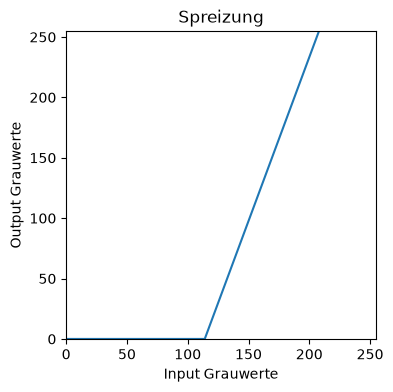

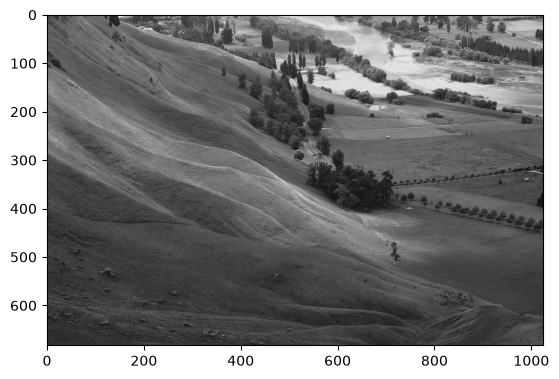

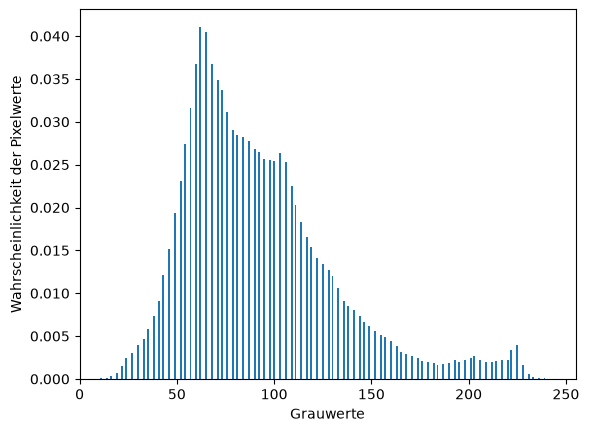

In [ ]:
# 2. Spreizung auf [0, L-1]
T_spreiz = np.clip((r - r_min) * (L - 1) / (r_max - r_min), 0, L - 1)
img_spreiz = zeige_transformation(T_spreiz, img, "Spreizung")

r_min = 0  r_max = 255


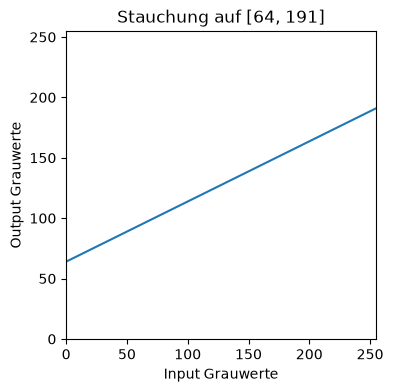

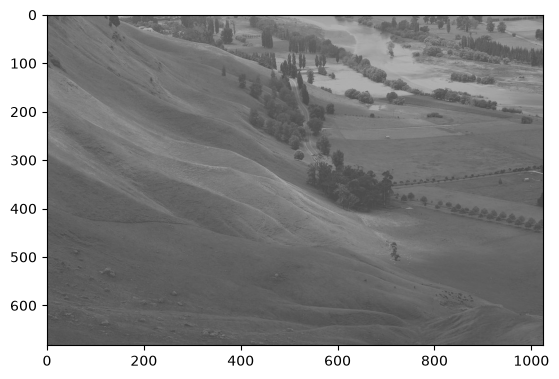

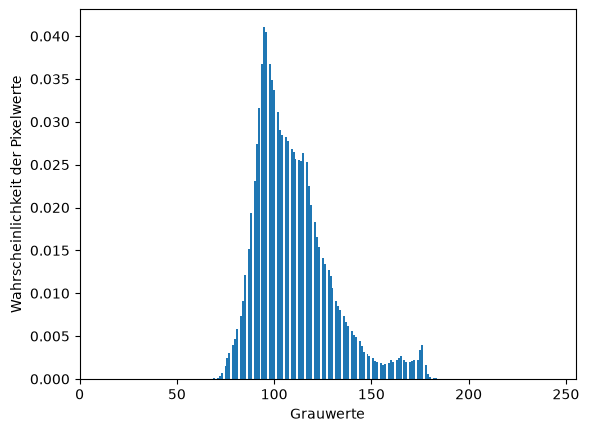

In [ ]:
# 3. Stauchung des gespreizten Bildes auf [64, 191]
s_min, s_max = 64, 191
r_min, r_max = min(img_spreiz.flatten()), max(img_spreiz.flatten())
print("r_min =", r_min, " r_max =", r_max)
T_stauch = np.clip((r - r_min) * (s_max - s_min) / (r_max - r_min) + s_min, s_min, s_max)
img_stauch = zeige_transformation(T_stauch, img_spreiz, "Stauchung auf [64, 191]")

### Histogrammbegrenzung (Clipping)

Statt $r_{min}$ und $r_{max}$ aus dem Bild zu nehmen, legt man **untere und obere Grenzen** selbst fest (fest gewählt oder über Perzentile, z. B. 1 % und 99 %). Werte außerhalb werden auf $0$ bzw. $L-1$ gesetzt, der Bereich dazwischen wird gespreizt:

$T(r) = \begin{cases}0 & \text{falls } r < r_{u}\\ (L-1)\,\frac{r-r_{u}}{r_{o}-r_{u}} & \text{falls } r_{u}\leq r\leq r_{o}\\ L-1 & \text{falls } r > r_{o}\end{cases}$

$r_u, r_o$ untere bzw. obere Grenze

Im Unterschied zur Spreizung gehen hier Informationen verloren: alle Pixel unter $r_u$ bzw. über $r_o$ werden ununterscheidbar.

**Aufgabe:** Konstruieren Sie die Transformation `T` für $r_u = 120$, $r_o = 200$. Bestimmen Sie anschließend die Grenzen über das 1 %- und 99 %-Perzentil (`np.percentile`).

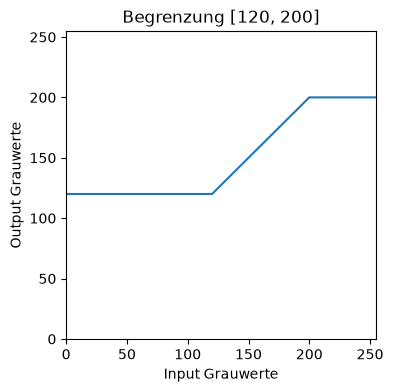

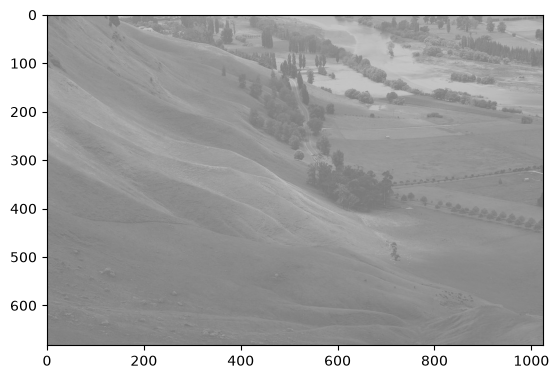

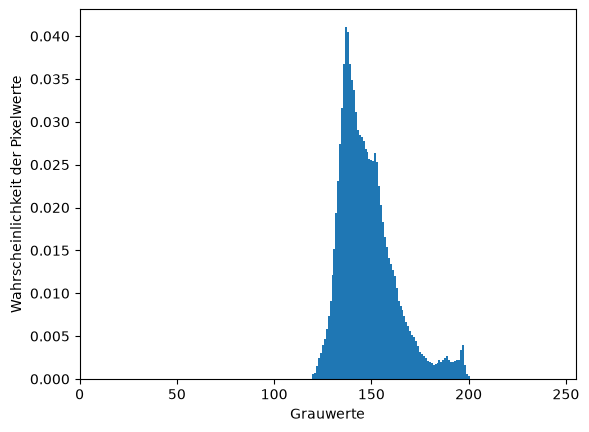

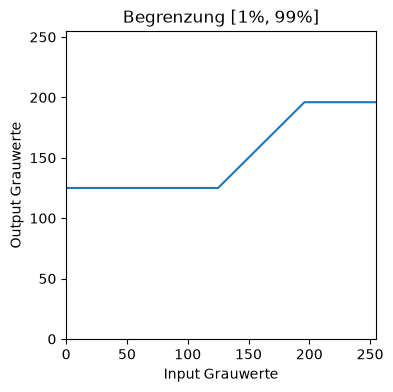

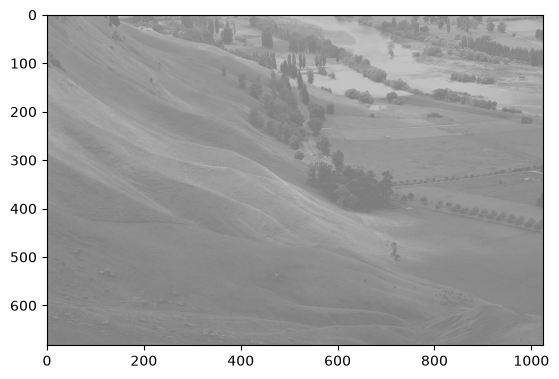

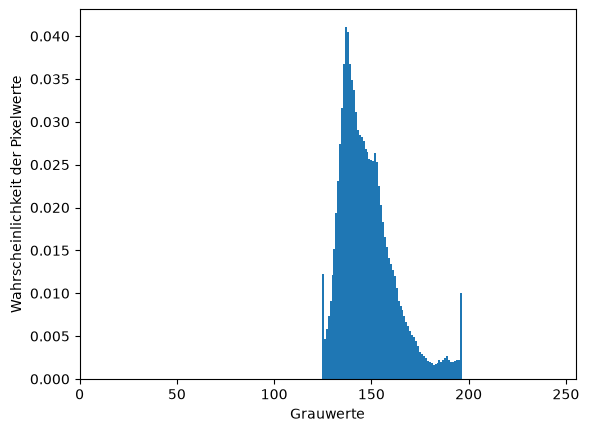

In [ ]:
r_u, r_o = 120, 200

T = np.clip(r, r_u, r_o)  # Skalierung und Sättigung

img_clip = zeige_transformation(T, img, "Begrenzung [120, 200]")

# Grenzen über das 1 %- und 99 %-Perzentil bestimmen und erneut anwenden
r_u = np.percentile(img.flatten(), 1)
r_o = np.percentile(img.flatten(), 99)
T = np.clip(r, r_u, r_o)
img_clip = zeige_transformation(T, img, "Begrenzung [1%, 99%]")

### Histogrammäqualisierung (Histogrammausgleich)

Für die Äqualisierung benötigen wir die **kumulierte Verteilungsfunktion** (cumulative distribution function, cdf). Sie gibt an, mit welcher Wahrscheinlichkeit ein Pixel einen Grauwert **kleiner oder gleich** $i$ hat:

$\mathrm{cdf}(i)=\sum_{j=0}^{i}p(j)$

$p$ Wahrscheinlichkeit (normiertes Histogramm)\
$i$ Grauwert

**Aufgabe:** Berechnen Sie die kumulierte Verteilungsfunktion.

Tipp: [`np.cumsum()`](https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html)

cdf(255) = 1.0


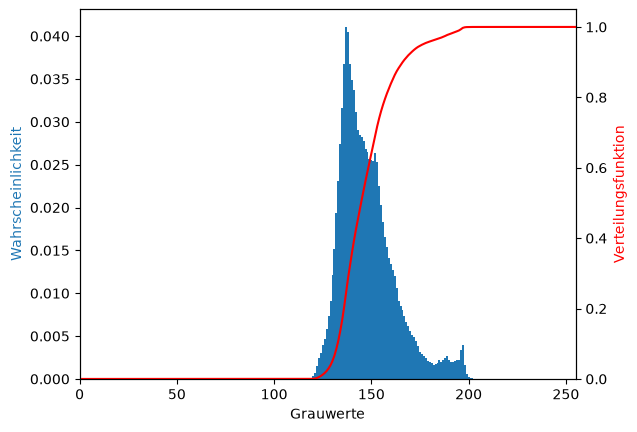

In [ ]:
cdf = np.cumsum(hist_n)  # kumulierte Summe der Wahrscheinlichkeiten
print("cdf(255) =", cdf[-1])      # muss 1 sein

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.bar(np.arange(L), hist_n, width=1)
ax2.plot(np.arange(L), cdf, "r")
ax1.set_xlabel("Grauwerte")
ax1.set_ylabel("Wahrscheinlichkeit", color="tab:blue")
ax2.set_ylabel("Verteilungsfunktion", color="r")
ax2.set_ylim([0, 1.05])
ax1.set_xlim([0, L - 1])
plt.show()

Die $\mathrm{cdf}$ liegt im Intervall $[0, 1]$. Für die Transformation wird sie auf den Grauwertbereich $[0, L-1]$ skaliert und auf ganze Zahlen gerundet:

$s = T(r) = \mathrm{round}\left((L-1)\sum_{j=0}^{r}\frac{n_j}{n}\right)$

Der Datentyp muss am Ende ein Integer (`np.uint8`) sein, damit `T` als Lookup-Table verwendet werden kann.

**Aufgabe:** Berechnen Sie aus der Verteilungsfunktion die Transformation.

In [ ]:
T_eq = (L - 1) * cdf
T_eq = T_eq.astype(int)

Im letzten Schritt wird die Transformation auf das ursprüngliche Bild angewendet.

**Aufgabe:** Wenden Sie `T_eq` auf `img` an.

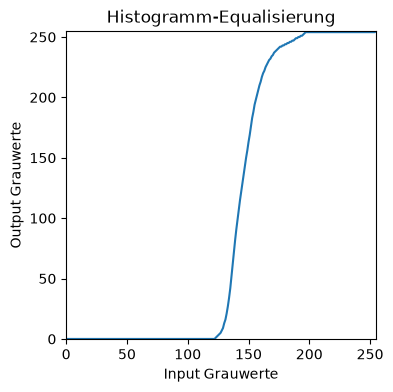

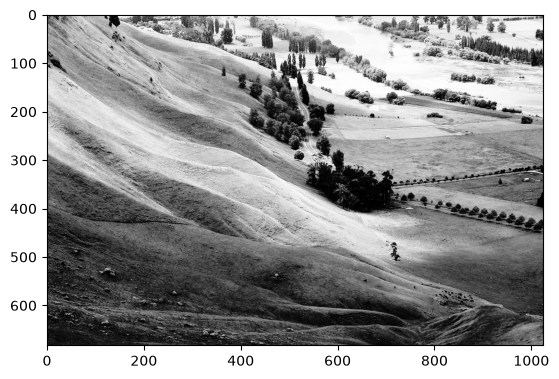

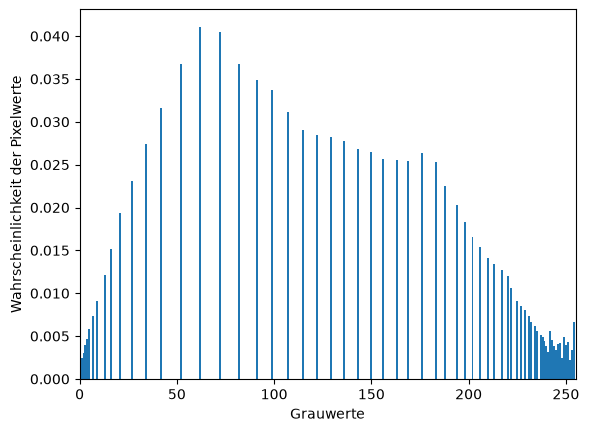

In [ ]:
img_eq = zeige_transformation(T_eq, img, "Histogramm-Equalisierung")

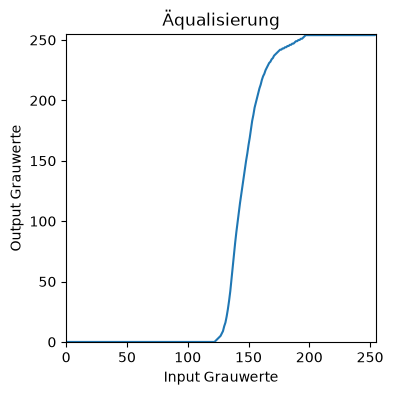

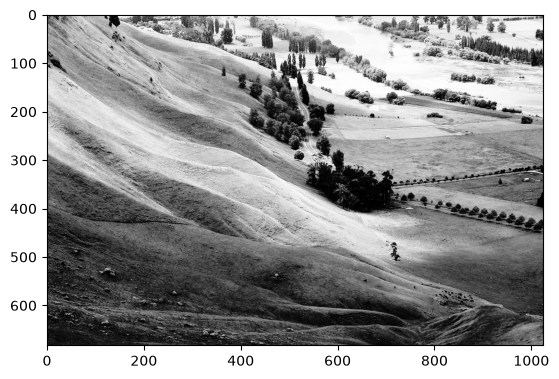

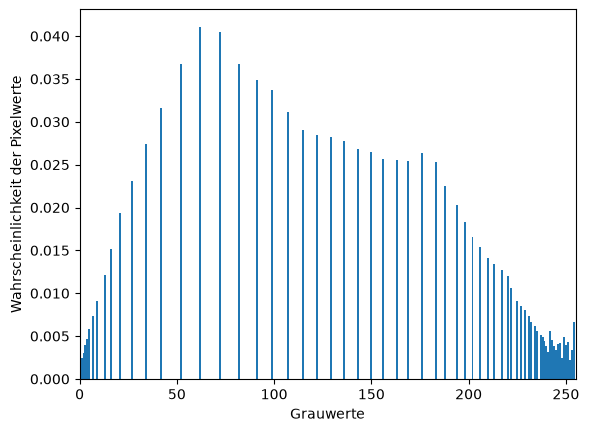

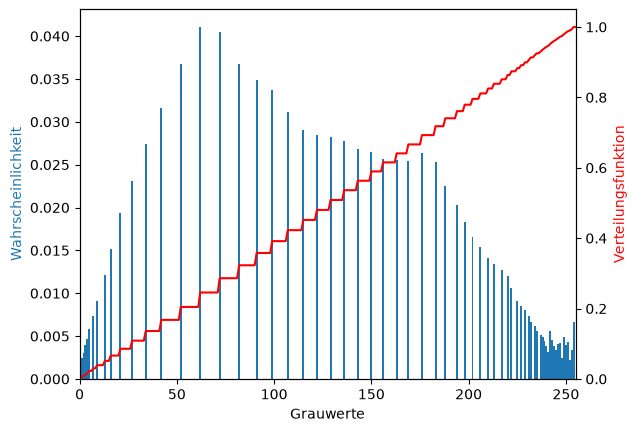

In [ ]:
# Kennlinie, Bild und Histogramm des äqualisierten Bildes
zeige_transformation(T_eq, img, "Äqualisierung")

# Histogramm und cdf des Ergebnisses
p_eq = np.bincount(img_eq.ravel(), minlength=L) / img_eq.size
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.bar(np.arange(L), p_eq, width=1)
ax2.plot(np.arange(L), np.cumsum(p_eq), "r")
ax1.set_xlabel("Grauwerte")
ax1.set_ylabel("Wahrscheinlichkeit", color="tab:blue")
ax2.set_ylabel("Verteilungsfunktion", color="r")
ax2.set_ylim([0, 1.05])
ax1.set_xlim([0, L - 1])
plt.show()

Die $\mathrm{cdf}$ ist jetzt annähernd linear, die Grauwerte nutzen den gesamten Bereich. Das Histogramm ist aber **nicht exakt flach**: Alle Pixel eines Grauwerts werden auf denselben neuen Wert abgebildet, Bins können also nur verschoben, nicht aufgeteilt werden. Deshalb entstehen Lücken zwischen den Balken.

**Fragen:**
* Wie viele verschiedene Grauwerte enthält das Bild vor und nach der Äqualisierung? (`np.unique`)
* Warum kann die Äqualisierung die Zahl der Grauwerte nie erhöhen?

In [ ]:
anzahl_grauwerte = np.unique(img).size - 1
print("Anzahl der Grauwerte:", anzahl_grauwerte)

anzahl_grauwerte_eq = np.unique(img_eq).size - 1
print("Anzahl der Grauwerte:", anzahl_grauwerte_eq)

Anzahl der Grauwerte: 95
Anzahl der Grauwerte: 67


In [ ]:
# OpenCV-Implementierung zum Vergleich
img_eq_cv = cv2.equalizeHist(img)
print("max. Abweichung zur eigenen Implementierung:", np.abs(img_eq_cv.astype(int) - img_eq.astype(int)).max())

max. Abweichung zur eigenen Implementierung: 1


*Hinweis:* OpenCV verwendet die Variante $s = \mathrm{round}\left((L-1)\,\frac{\mathrm{cdf}(r)-\mathrm{cdf}_{min}}{1-\mathrm{cdf}_{min}}\right)$, damit der kleinste vorkommende Grauwert sicher auf 0 abgebildet wird. Bei wenigen Pixeln mit dem kleinsten Grauwert ist der Unterschied vernachlässigbar.

### CLAHE

Bei der **Contrast Limited Adaptive Histogram Equalization (CLAHE)** wird das Bild in ein Raster aus Kacheln (*tiles*) unterteilt und für jede Kachel eine eigene Äqualisierung berechnet:

* **Adaptiv:** Jede Kachel bekommt ihre eigene Kennlinie. Zwischen den Kacheln wird bilinear interpoliert, damit keine Kachelkanten sichtbar werden. Dadurch werden Kontraste in Regionen sichtbar, die bei der globalen Äqualisierung untergehen.
* **Contrast Limited:** Vor der Berechnung der cdf wird jedes Kachel-Histogramm bei einem Grenzwert abgeschnitten; der Überschuss wird gleichmäßig auf alle Bins verteilt. Das begrenzt die Steigung der Kennlinie und verhindert, dass Rauschen in homogenen Flächen extrem verstärkt wird.

Achtung: CLAHE ist **keine reine Punktoperation** mehr – die Transformation eines Pixels hängt von seiner Position bzw. Umgebung ab.

Argumente:\
`clipLimit`: Grenzwert für das Abschneiden der Histogramme (größer = stärkerer Kontrast; OpenCV-Standard 40, üblich sind ca. 2–4)\
`tileGridSize`: Anzahl der Kacheln in Zeilen- und Spaltenrichtung, z. B. `(8, 8)`

**Aufgabe:** Variieren Sie `clipLimit` (z. B. 1, 2, 10, 40) und `tileGridSize` (z. B. (2, 2), (8, 8), (32, 32)). Wie verändert sich das Ergebnis?

In [ ]:
clahe = cv2.createCLAHE(clipLimit=1, tileGridSize=(8, 8))
img_clahe = clahe.apply(img)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, bild, titel in zip(ax, [img, img_eq, img_clahe], ["Original", "Histogrammäqualisierung", "CLAHE"]):
    a.imshow(bild, cmap="gray", vmin=0, vmax=L - 1)
    a.set_title(titel)
    a.axis("off")
plt.tight_layout()
plt.show()

NameError: name 'img' is not defined